# Exploratory Data Analysis (EDA): The Narratives fMRI Dataset (`ds002345`)

This notebook provides an end-to-end exploratory analysis of the **Narratives** dataset (Nastase et al., 2021; OpenNeuro `ds002345` & `ds002345-fmriprep`):

1. **Setup & Local Metadata Sync:** Load `participants.tsv`, `participants.json`, and `dataset_description.json` (auto-downloading lightweight metadata from `OpenNeuroDatasets/ds002345` if not cached locally).
2. **Participant & Scan-Level EDA:** Unpack comma-separated multi-story entries per participant into a tidy `(participant, task, condition, comprehension)` table.
3. **Story / Task Coverage & Demographics:** Analyze subject counts per story, age/sex distributions, and comprehension scores across the 27+ stories.
4. **Local `ds002345-fmriprep` Inventory:** Inspect local subject folders, functional runs, anatomical/surface outputs, and distinguish **git-annex pointer files** (`0 KB` / symlink pointers) from **materialized (`datalad get`) NIfTI/GIfTI files**.
5. **On-Demand Functional / Voxel Inspection:** Helper function to fetch (`datalad get` or S3 HTTP download) and inspect a single subject/story BOLD volume or surface file with `nibabel`.

In [1]:
from pathlib import Path
import json
import re
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

ROOT_DIR = Path(r"C:\Users\srishtysuman\OfflineRepo\NS_Implem")
FMRIPREP_DIR = ROOT_DIR / "ds002345-fmriprep"
META_CACHE_DIR = ROOT_DIR / "data" / "narratives_meta"
META_CACHE_DIR.mkdir(parents=True, exist_ok=True)

def download_if_missing(url: str, dest: Path) -> Path:
    """Download using Windows native curl.exe (uses Windows Schannel TLS store)."""
    if not dest.exists():
        dest.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(["curl.exe", "-fSL", url, "-o", str(dest)], check=True)
        print(f"Downloaded: {dest.name}")
    return dest

OPENNEURO_RAW_BASE = "https://raw.githubusercontent.com/OpenNeuroDatasets/ds002345/1.1.4"
for fname in ["participants.tsv", "participants.json", "dataset_description.json", "README"]:
    download_if_missing(f"{OPENNEURO_RAW_BASE}/{fname}", META_CACHE_DIR / fname)

print(f"fMRIPrep directory exists: {FMRIPREP_DIR.exists()} -> {FMRIPREP_DIR}")
print(f"Metadata cache directory : {META_CACHE_DIR}")

fMRIPrep directory exists: True -> C:\Users\srishtysuman\OfflineRepo\NS_Implem\ds002345-fmriprep
Metadata cache directory : C:\Users\srishtysuman\OfflineRepo\NS_Implem\data\narratives_meta


In [2]:
# Load dataset description and raw participants table
with open(META_CACHE_DIR / "dataset_description.json", "r", encoding="utf-8") as f:
    dataset_desc = json.load(f)

print("Dataset Name:", dataset_desc.get("Name"))
print("BIDS Version:", dataset_desc.get("BIDSVersion"))
print("Authors     :", ", ".join(dataset_desc.get("Authors", [])[:6]), "...")

df_participants_raw = pd.read_csv(META_CACHE_DIR / "participants.tsv", sep="\t")
print(f"\nRaw participants table shape: {df_participants_raw.shape} (1 row per unique subject)")
display(df_participants_raw.head(10))

Dataset Name: Narratives
BIDS Version: 1.2.1
Authors     : Samuel A. Nastase, Yun-Fei Liu, Hanna Hillman, Asieh Zadbood, Liat Hasenfratz, Neggin Keshavarzian ...

Raw participants table shape: (345, 6) (1 row per unique subject)


,participant_id,age,sex,task,condition,comprehension
0,sub-001,"22,23","F,F","pieman,tunnel","n/a,n/a","n/a,n/a"
1,sub-002,20,M,pieman,NaN,NaN
2,sub-003,NaN,F,pieman,NaN,NaN
3,sub-004,"24,24","M,M","pieman,tunnel","n/a,n/a","n/a,n/a"
4,sub-005,"n/a,n/a","M,M","pieman,tunnel","n/a,n/a","n/a,n/a"
5,sub-006,21,F,pieman,NaN,NaN
6,sub-007,45,M,pieman,NaN,NaN
7,sub-008,NaN,M,pieman,NaN,NaN
8,sub-009,19,M,pieman,NaN,NaN
9,sub-010,20,F,pieman,NaN,NaN


In [3]:
for column in ["condition", "comprehension"]:
    nonempty = df_participants_raw[column].apply(
        lambda value: any(
            entry.strip().lower() not in {"", "n/a", "nan", "none"}
            for entry in str(value).split(",")
        )
    )
    print(f"\n{column}: {nonempty.sum()} participants with non-empty entries")
    display(df_participants_raw.loc[nonempty, ["participant_id", "task", column]])


condition: 199 participants with non-empty entries


,participant_id,task,condition
15,sub-016,"pieman,slumlordreach,notthefallintact,notthefa...","n/a,n/a,intact-shortscram,intact-shortscram"
22,sub-023,"pieman,prettymouth,milkyway","n/a,affair,vodka"
29,sub-030,"pieman,prettymouth,milkyway","n/a,paranoia,vodka"
31,sub-032,"pieman,prettymouth,milkyway","n/a,affair,vodka"
33,sub-034,"pieman,prettymouth,milkyway,notthefallintact,n...","n/a,affair,original,intact-longscram,intact-lo..."
...,...,...,...
340,sub-341,"notthefallintact,notthefalllongscram","intact-longscram,intact-longscram"
341,sub-342,"notthefallintact,notthefallshortscram","intact-shortscram,intact-shortscram"
342,sub-343,"notthefallintact,notthefallshortscram","intact-shortscram,intact-shortscram"
343,sub-344,"notthefallintact,notthefalllongscram","intact-longscram,intact-longscram"



comprehension: 179 participants with non-empty entries


,participant_id,task,comprehension
15,sub-016,"pieman,slumlordreach,notthefallintact,notthefa...","n/a,0.569,n/a,n/a"
22,sub-023,"pieman,prettymouth,milkyway","n/a,0.889,1.0"
29,sub-030,"pieman,prettymouth,milkyway","n/a,0.963,0.893"
31,sub-032,"pieman,prettymouth,milkyway","n/a,0.963,0.964"
33,sub-034,"pieman,prettymouth,milkyway,notthefallintact,n...","n/a,1.0,1.0,n/a,n/a"
...,...,...,...
310,sub-311,"piemanpni,bronx,forgot,black","0.517,0.58,0.58,0.66"
311,sub-312,"piemanpni,bronx,forgot,black","0.7,0.7,0.7,0.84"
312,sub-313,"piemanpni,bronx,forgot,black","0.833,0.82,0.82,0.88"
313,sub-314,"piemanpni,bronx,forgot,black","0.767,0.78,0.78,0.92"


## 1. Unpack Multi-Story Entries into a Scan-Level DataFrame

In `participants.tsv`, subjects who listened to multiple stories have comma-separated lists in `age`, `sex`, `task`, `condition`, and `comprehension` (e.g., `task = "pieman,tunnel"`). Let's explode those into a clean scan-level table where **each row is one `(subject, story/task)` functional scan**.

In [4]:
def expand_participants_to_scans(df_raw: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for _, row in df_raw.iterrows():
        pid = str(row["participant_id"]).strip()
        tasks = [x.strip() for x in str(row["task"]).split(",")]
        ages = [x.strip() for x in str(row["age"]).split(",")]
        sexes = [x.strip() for x in str(row["sex"]).split(",")]
        conds = [x.strip() for x in str(row["condition"]).split(",")]
        comps = [x.strip() for x in str(row["comprehension"]).split(",")]

        n = len(tasks)
        # Broadcast single values if a column was not repeated n times
        if len(ages) < n:
            ages = (ages * n)[:n]
        if len(sexes) < n:
            sexes = (sexes * n)[:n]
        if len(conds) < n:
            conds = (conds * n)[:n]
        if len(comps) < n:
            comps = (comps * n)[:n]

        for i in range(n):
            age_val = pd.to_numeric(ages[i], errors="coerce")
            comp_val = pd.to_numeric(comps[i], errors="coerce")
            rows.append({
                "participant_id": pid,
                "sub_num": int(pid.replace("sub-", "")),
                "in_fmriprep_200": int(pid.replace("sub-", "")) <= 200,
                "scan_order_for_subject": i + 1,
                "task": tasks[i],
                "condition": None if conds[i] in ("n/a", "nan", "") else conds[i],
                "age": age_val,
                "sex": None if sexes[i] in ("n/a", "nan", "") else sexes[i],
                "comprehension": comp_val,
            })
    return pd.DataFrame(rows)

df_scans = expand_participants_to_scans(df_participants_raw)
print(f"Total unique participants : {df_scans['participant_id'].nunique()}")
print(f"Total subject-story scans : {len(df_scans)}")
print(f"Unique story tasks        : {df_scans['task'].nunique()}")
display(df_scans.head(12))

Total unique participants : 345
Total subject-story scans : 769
Unique story tasks        : 19


,participant_id,sub_num,in_fmriprep_200,scan_order_for_subject,task,condition,age,sex,comprehension
0,sub-001,1,True,1,pieman,NaN,22.0,F,NaN
1,sub-001,1,True,2,tunnel,NaN,23.0,F,NaN
2,sub-002,2,True,1,pieman,NaN,20.0,M,NaN
3,sub-003,3,True,1,pieman,NaN,NaN,F,NaN
4,sub-004,4,True,1,pieman,NaN,24.0,M,NaN
5,sub-004,4,True,2,tunnel,NaN,24.0,M,NaN
6,sub-005,5,True,1,pieman,NaN,NaN,M,NaN
7,sub-005,5,True,2,tunnel,NaN,NaN,M,NaN
8,sub-006,6,True,1,pieman,NaN,21.0,F,NaN
9,sub-007,7,True,1,pieman,NaN,45.0,M,NaN


,task,total_scans,unique_subjects,subjects_in_fmriprep_200,mean_age,pct_female,mean_comprehension,n_comprehension
0,pieman,82,82,82,22.5,54.9%,nan,0
1,shapessocial,59,59,10,22.4,71.2%,8.722,18
2,shapesphysical,59,59,10,22.4,71.2%,8.722,18
3,notthefallintact,56,56,25,20.9,55.4%,nan,0
4,milkyway,53,53,53,21.0,50.9%,0.932,36
5,bronx,47,47,1,23.2,70.2%,0.575,46
6,forgot,47,47,1,23.2,70.2%,0.575,46
7,black,47,47,1,23.2,70.2%,0.753,46
8,piemanpni,47,47,1,23.2,70.2%,0.638,47
9,prettymouth,40,40,40,21.1,47.5%,0.937,40


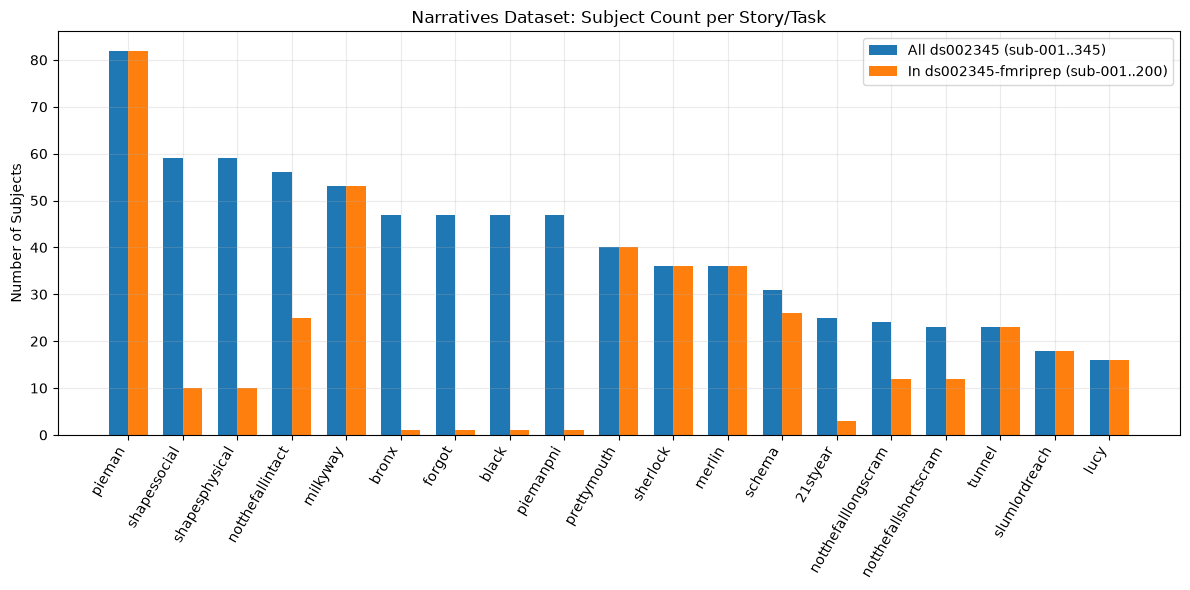

In [5]:
# Summarize story coverage across full dataset (345 subjects) vs ds002345-fmriprep (sub-001..sub-200)
story_summary = (
    df_scans.groupby("task")
    .agg(
        total_scans=("participant_id", "count"),
        unique_subjects=("participant_id", "nunique"),
        subjects_in_fmriprep_200=("in_fmriprep_200", "sum"),
        mean_age=("age", "mean"),
        pct_female=("sex", lambda s: (s == "F").mean() * 100 if s.notna().any() else np.nan),
        mean_comprehension=("comprehension", "mean"),
        n_comprehension=("comprehension", lambda s: s.notna().sum()),
    )
    .sort_values("total_scans", ascending=False)
    .reset_index()
)

display(story_summary.style.format({
    "mean_age": "{:.1f}",
    "pct_female": "{:.1f}%",
    "mean_comprehension": "{:.3f}",
}))

# Plot total subjects vs subjects available in ds002345-fmriprep (sub-001..sub-200)
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(story_summary))
ax.bar(x - 0.18, story_summary["unique_subjects"], width=0.36, label="All ds002345 (sub-001..345)")
ax.bar(x + 0.18, story_summary["subjects_in_fmriprep_200"], width=0.36, label="In ds002345-fmriprep (sub-001..200)")
ax.set_xticks(x)
ax.set_xticklabels(story_summary["task"], rotation=60, ha="right")
ax.set_ylabel("Number of Subjects")
ax.set_title("Narratives Dataset: Subject Count per Story/Task")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Inspect Local `ds002345-fmriprep` Directory & Checkout Progress

Because DataLad/git-annex datasets store heavy neuroimaging files (`.nii.gz`, `.gii`, `.h5`) as annex pointers until `datalad get` is run, this cell checks:
1. How many subject directories (`sub-*`) are currently checked out in `ds002345-fmriprep`.
2. What functional runs and tasks exist locally in `sub-*/func/`.
3. Which files are annex pointers (`0 bytes` / symlink target strings) vs. downloaded binary files.

In [6]:
def inspect_local_fmriprep(fmriprep_dir: Path) -> pd.DataFrame:
    sub_dirs = sorted(
        [d for d in fmriprep_dir.iterdir() if d.is_dir() and re.match(r"^sub-\d+$", d.name)]
    ) if fmriprep_dir.exists() else []
    fs_dirs = sorted(
        [d for d in (fmriprep_dir / "sourcedata" / "freesurfer").iterdir() if d.is_dir() and re.match(r"^sub-\d+$", d.name)]
    ) if (fmriprep_dir / "sourcedata" / "freesurfer").exists() else []

    print(f"Top-level subject folders checked out : {len(sub_dirs)} / 200")
    print(f"FreeSurfer subject folders checked out: {len(fs_dirs)} / 200")
    if sub_dirs:
        print(f"Range of top-level subjects           : {sub_dirs[0].name} .. {sub_dirs[-1].name}")

    func_records = []
    for sdir in sub_dirs:
        fdir = sdir / "func"
        if not fdir.exists():
            continue
        for fpath in fdir.iterdir():
            m = re.match(r"^(sub-\d+)_task-([a-zA-Z0-9]+?)(?:_run-(\d+))?_(.+)$", fpath.name)
            if m:
                sub_id, task, run, suffix = m.groups()
                size_bytes = fpath.stat().st_size if fpath.exists() else 0
                func_records.append({
                    "participant_id": sub_id,
                    "task": task,
                    "run": run or "1",
                    "suffix": suffix,
                    "size_bytes": size_bytes,
                    "is_materialized": size_bytes > 1024,  # >1 KB means actual file content, not annex pointer
                    "path": str(fpath),
                })
    return pd.DataFrame(func_records)

df_local_func = inspect_local_fmriprep(FMRIPREP_DIR)
if not df_local_func.empty:
    print(f"\nIndexed {len(df_local_func):,} files across local sub-*/func/ directories.")
    local_task_counts = (
        df_local_func.groupby("task")
        .agg(
            local_subjects=("participant_id", "nunique"),
            total_files=("path", "count"),
            materialized_files=("is_materialized", "sum"),
        )
        .sort_values("local_subjects", ascending=False)
    )
    display(local_task_counts)
    display(df_local_func["suffix"].value_counts().rename("count").to_frame().head(15))
else:
    print("No sub-*/func directories found yet.")

Top-level subject folders checked out : 100 / 200
FreeSurfer subject folders checked out: 200 / 200
Range of top-level subjects           : sub-001 .. sub-100

Indexed 2,100 files across local sub-*/func/ directories.


,local_subjects,total_files,materialized_files
task,,,
pieman,82,960,0
prettymouth,28,280,0
tunnel,23,230,0
milkyway,21,210,0
lucy,16,160,0
notthefall,3,30,0
schema,3,120,0
shapesphysical,3,30,0
shapessocial,3,30,0


,count
suffix,
desc-coreg_boldref.json,210
desc-coreg_boldref.nii.gz,210
desc-hmc_boldref.json,210
desc-hmc_boldref.nii.gz,210
from-boldref_to-T1w_mode-image_desc-coreg_xfm.json,210
from-boldref_to-T1w_mode-image_desc-coreg_xfm.txt,210
from-orig_to-boldref_mode-image_desc-hmc_xfm.json,210
from-orig_to-boldref_mode-image_desc-hmc_xfm.txt,210
from-boldref_to-auto00000_mode-image_xfm.json,99


## 3. Fetch & Inspect a Sample Voxel-Wise 4D BOLD Scan (`nibabel`)

All OpenNeuro `ds002345` files are publicly hosted on AWS S3 (`https://s3.amazonaws.com/openneuro.org/ds002345/`), which means you can either use `datalad get` **or** stream/download any specific subject + story scan directly over HTTPS without waiting for full repository checkouts.

Below is a helper to download and inspect a single subject's scan (`sub-001`, story `pieman`, run `1`) and plot its voxel-wise dimensions, brain mask, and sample voxel time series.

In [7]:
import nibabel as nib

SAMPLE_DIR = META_CACHE_DIR / "sample_sub-001"
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

S3_BASE = "https://s3.amazonaws.com/openneuro.org/ds002345"
sample_rel_json = "sub-001/func/sub-001_task-pieman_run-1_bold.json"
sample_rel_nii = "sub-001/func/sub-001_task-pieman_run-1_bold.nii.gz"

local_json = download_if_missing(f"{S3_BASE}/{sample_rel_json}", SAMPLE_DIR / Path(sample_rel_json).name)
local_nii = download_if_missing(f"{S3_BASE}/{sample_rel_nii}", SAMPLE_DIR / Path(sample_rel_nii).name)

with open(local_json, "r", encoding="utf-8") as f:
    bold_meta = json.load(f)

print("=== Sample Scan BIDS Sidecar Metadata (sub-001, task-pieman, run-1) ===")
for k in ["TaskName", "RepetitionTime", "EchoTime", "FlipAngle", "Manufacturer", "ManufacturersModelName", "SliceTiming"]:
    if k in bold_meta:
        val = bold_meta[k]
        print(f"  {k:24s}: {val if not isinstance(val, list) else f'list of len {len(val)}'}")

img = nib.load(str(local_nii))
data_4d = img.get_fdata(dtype=np.float32)  # shape: (X, Y, Z, T)
voxel_sizes = img.header.get_zooms()[:3]
tr_sec = img.header.get_zooms()[3]

print("\n=== Voxel-Wise 4D NIfTI Summary ===")
print(f"  File              : {local_nii.name}")
print(f"  4D Shape          : {data_4d.shape}  -> (X={data_4d.shape[0]}, Y={data_4d.shape[1]}, Z={data_4d.shape[2]} voxels, T={data_4d.shape[3]} TRs)")
print(f"  Voxel Size        : {voxel_sizes} mm")
print(f"  TR                : {tr_sec} s (total duration = {data_4d.shape[3] * tr_sec:.1f} s)")
print(f"  Total grid voxels : {np.prod(data_4d.shape[:3]):,}")

=== Sample Scan BIDS Sidecar Metadata (sub-001, task-pieman, run-1) ===
  TaskName                : pieman
  RepetitionTime          : 1.5
  EchoTime                : 0.028
  FlipAngle               : 64
  Manufacturer            : Siemens
  ManufacturersModelName  : Skyra
  SliceTiming             : list of len 27

=== Voxel-Wise 4D NIfTI Summary ===
  File              : sub-001_task-pieman_run-1_bold.nii.gz
  4D Shape          : (64, 64, 27, 300)  -> (X=64, Y=64, Z=27 voxels, T=300 TRs)
  Voxel Size        : (3.0, 3.0, 4.0) mm
  TR                : 1.5 s (total duration = 450.0 s)
  Total grid voxels : 110,592


Estimated in-brain voxels: 81,629 / 110,592


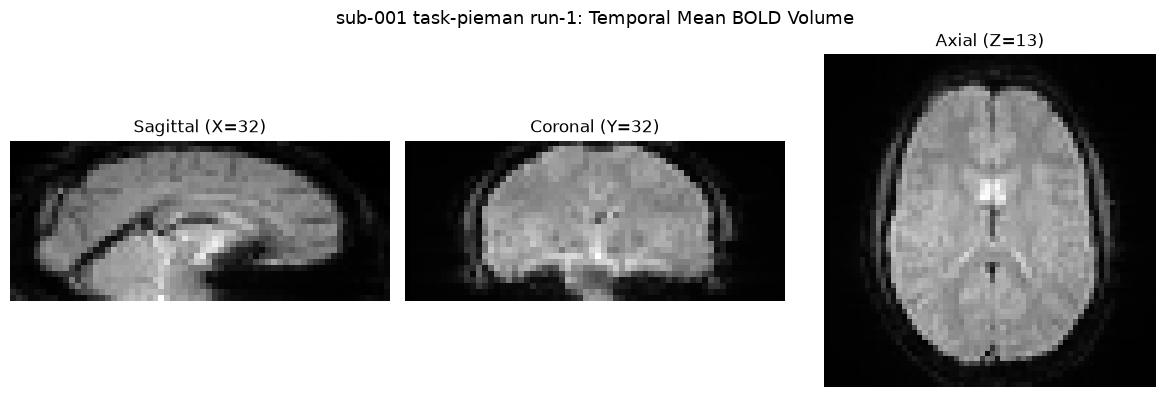

Voxel response matrix Y_voxels shape: (300, 81629) -> (n_TRs, n_brain_voxels)


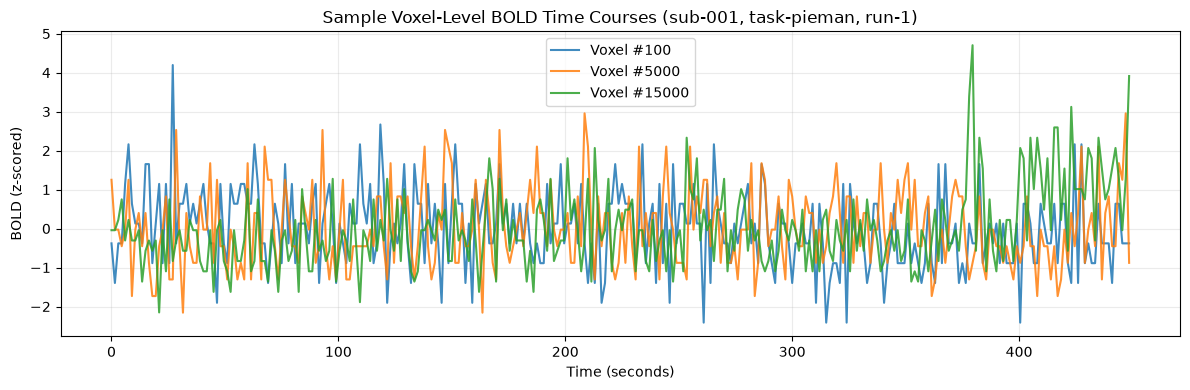

In [8]:
# Compute temporal mean image and simple intensity brain mask
mean_vol = data_4d.mean(axis=-1)
brain_mask = mean_vol > np.percentile(mean_vol[mean_vol > 0], 25)
n_brain_voxels = int(brain_mask.sum())
print(f"Estimated in-brain voxels: {n_brain_voxels:,} / {np.prod(data_4d.shape[:3]):,}")

# Plot orthogonal middle slices + 3 sample voxel time series
mid_x, mid_y, mid_z = [s // 2 for s in mean_vol.shape]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(np.rot90(mean_vol[mid_x, :, :]), cmap="gray")
axes[0].set_title(f"Sagittal (X={mid_x})")
axes[1].imshow(np.rot90(mean_vol[:, mid_y, :]), cmap="gray")
axes[1].set_title(f"Coronal (Y={mid_y})")
axes[2].imshow(np.rot90(mean_vol[:, :, mid_z]), cmap="gray")
axes[2].set_title(f"Axial (Z={mid_z})")
for ax in axes:
    ax.axis("off")
plt.suptitle("sub-001 task-pieman run-1: Temporal Mean BOLD Volume", fontsize=13)
plt.tight_layout()
plt.show()

# Extract (T, N_voxels) matrix for in-brain voxels and plot z-scored time series of 3 voxels
Y_voxels = data_4d[brain_mask].T  # shape: (T, N_voxels)
Y_voxels_z = (Y_voxels - Y_voxels.mean(axis=0, keepdims=True)) / (Y_voxels.std(axis=0, keepdims=True) + 1e-8)
print(f"Voxel response matrix Y_voxels shape: {Y_voxels_z.shape} -> (n_TRs, n_brain_voxels)")

time_axis = np.arange(Y_voxels_z.shape[0]) * tr_sec
fig, ax = plt.subplots(figsize=(12, 4))
for idx in [100, 5000, 15000]:
    if idx < Y_voxels_z.shape[1]:
        ax.plot(time_axis, Y_voxels_z[:, idx], alpha=0.85, label=f"Voxel #{idx}")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("BOLD (z-scored)")
ax.set_title("Sample Voxel-Level BOLD Time Courses (sub-001, task-pieman, run-1)")
ax.legend()
plt.tight_layout()
plt.show()